In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Generate spiral dataset (similar to Playground)
def generate_spiral_data(n_points=1000, n_arms=2):
    data = []
    labels = []
    for i in range(n_points // n_arms):
        for arm in range(n_arms):
            theta = np.linspace(0, 4*np.pi, n_points // n_arms)
            r = np.linspace(0.1, 1, n_points // n_arms)
            x = r * np.cos(theta + arm * np.pi)
            y = r * np.sin(theta + arm * np.pi)
            data.append(np.stack([x, y], axis=1))
            labels.append(np.full(len(x), arm))
    X = np.vstack(data)
    y = np.hstack(labels)
    return X, y

In [5]:
# Load data
X, y = generate_spiral_data(1000)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [6]:
# Model with tuned hyperparameters (4 hidden layers, 8 neurons, Tanh, LR=0.01)
model = tf.keras.Sequential([
    tf.keras.layers.Dense(8, activation='tanh', input_shape=(2,)),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(8, activation='tanh'),
    tf.keras.layers.Dense(2, activation='softmax')
])
model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

d:\anaconda\Lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# Train
history = model.fit(X_train, y_train, epochs=100, validation_data=(X_test, y_test), verbose=1)
# Final losses
train_loss = history.history['loss'][-1]
test_loss = history.history['val_loss'][-1]
print(f"Final Training Loss: {train_loss:.4f}")
print(f"Final Test Loss: {test_loss:.4f}")

Epoch 1/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 20s 2ms/step - accuracy: 1.0000 - loss: 7.9418e-05 - val_accuracy: 1.0000 - val_loss: 7.7998e-05
Epoch 2/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 25s 2ms/step - accuracy: 1.0000 - loss: 7.8456e-05 - val_accuracy: 1.0000 - val_loss: 7.6189e-05
Epoch 3/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - accuracy: 1.0000 - loss: 7.7481e-05 - val_accuracy: 1.0000 - val_loss: 7.5486e-05
Epoch 4/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - accuracy: 1.0000 - loss: 7.6577e-05 - val_accuracy: 1.0000 - val_loss: 7.4352e-05
Epoch 5/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 27s 3ms/step - accuracy: 1.0000 - loss: 7.5630e-05 - val_accuracy: 1.0000 - val_loss: 7.3750e-05
Epoch 6/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 28s 3ms/step - accuracy: 1.0000 - loss: 7.4735e-05 - val_accuracy: 1.0000 - val_loss: 7.4115e-05
Epoch 7/100
10938/10938 ━━━━━━━━━━━━━━━━━━━━ 24s 2ms/step - accuracy: 1.0000 - loss: 7.3819e-05 - val_accuracy: 1.0000 - val_loss: 7.2746e-05
Epoch 

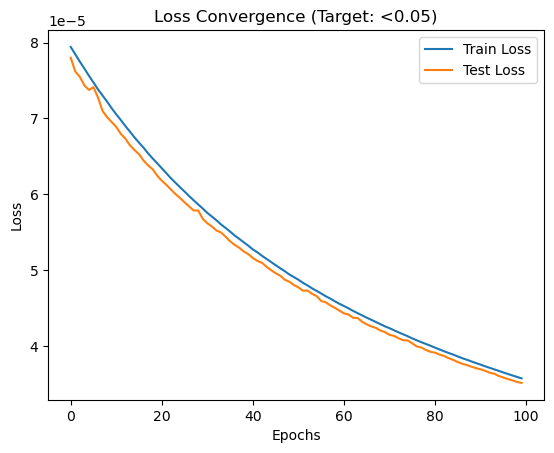

In [9]:
# Plot losses
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Convergence (Target: <0.05)')
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


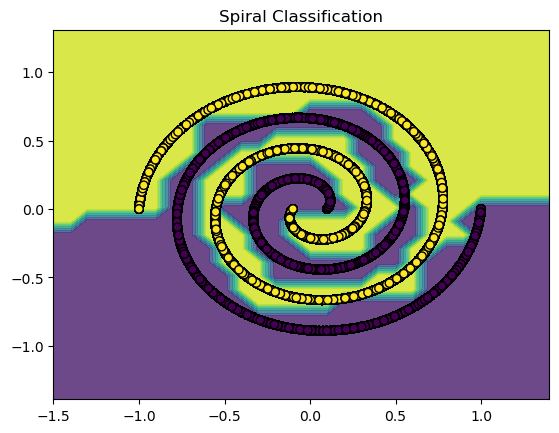

In [10]:
# Visualize predictions
def plot_predictions(model, X, y):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = np.argmax(Z, axis=1).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='black')
    plt.title('Spiral Classification')
    plt.show()
plot_predictions(model, np.vstack([X_train, X_test]), np.hstack([y_train, y_test]))